In [122]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [82]:
df=pd.read_csv("loan_approval_data.csv")
df.head()
df.info()
df.isnull().sum()
df.describe() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


Handle missing values


In [83]:
categorical_cols=df.select_dtypes(include=["object"]).columns
numerical_cols=df.select_dtypes(include=["number"]).columns

In [84]:
categorical_cols

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [85]:
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [86]:
from sklearn.impute import SimpleImputer
num_imp=SimpleImputer( strategy='mean')
df[numerical_cols]=num_imp.fit_transform(df[numerical_cols])

In [87]:
cat_imp=SimpleImputer( strategy='most_frequent')
df[categorical_cols]=cat_imp.fit_transform(df[categorical_cols])

Exploratory Data Analysis


Text(0.5, 1.0, ' is loan approved')

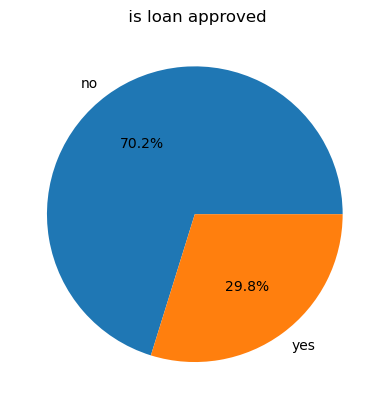

In [88]:
# how balanced our classes are?

classes_count=df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["no","yes"], autopct="%1.1f%%")
plt.title(" is loan approved"
)

[Text(0, 0, '621'), Text(0, 0, '379')]

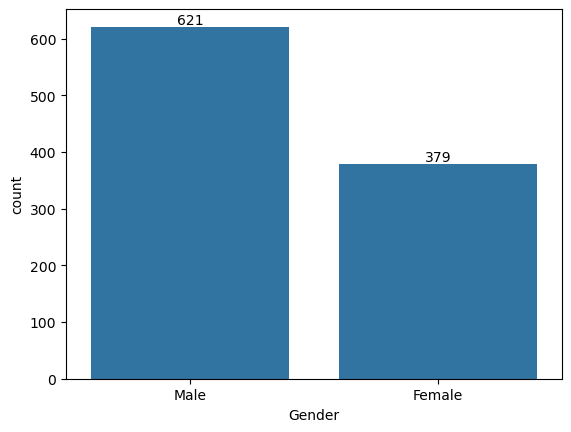

In [89]:
# analyze category
gender_cnt=df["Gender"].value_counts()
ax=sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

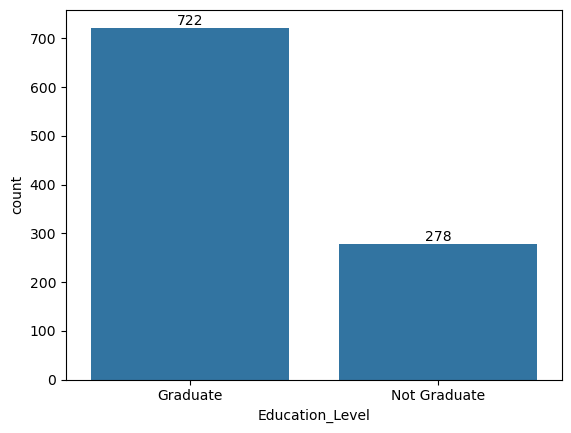

In [90]:
edu_level=df["Education_Level"].value_counts()
ax=sns.barplot(edu_level)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

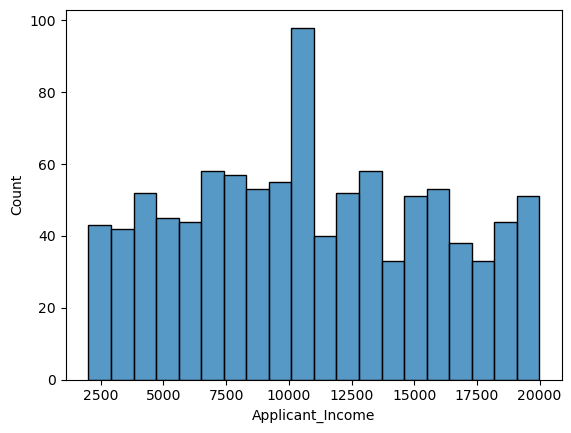

In [91]:
# analyze income
sns.histplot(
    data=df,
    x="Applicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

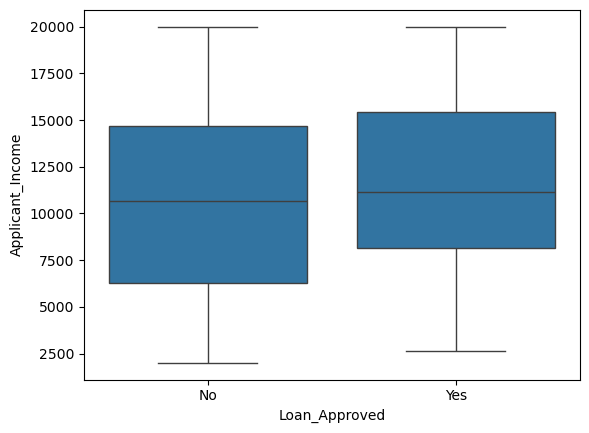

In [92]:
# outlier
sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

<Axes: xlabel='Loan_Approved', ylabel='Savings'>

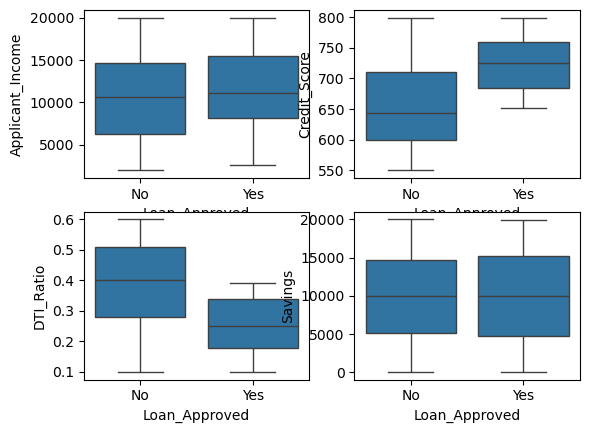

In [93]:
fig,axes=plt.subplots(2,2)

sns.boxplot(ax=axes[0,0],data=df, x="Loan_Approved", y="Applicant_Income")
sns.boxplot(ax=axes[0,1],data=df, x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax=axes[1,0],data=df, x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax=axes[1,1],data=df, x="Loan_Approved", y="Savings")


Encoding

In [94]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [95]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df["Education_Level"]=le.fit_transform(df["Education_Level"])
df["Loan_Approved"]=le.fit_transform(df["Loan_Approved"])



In [96]:
cols=["Employment_Status","Marital_Status","Loan_Purpose","Property_Area","Employer_Category","Gender"]
ohe=OneHotEncoder(drop="first",sparse_output=False,handle_unknown='ignore')
encoded=ohe.fit_transform(df[cols])
encode_df=pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols),index=df.index)
df=pd.concat([df.drop(columns=cols), encode_df],axis=1)

In [97]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male
0,1.0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,2.0,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
2,3.0,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,4.0,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,5.0,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


Correation Heatmap

<Axes: >

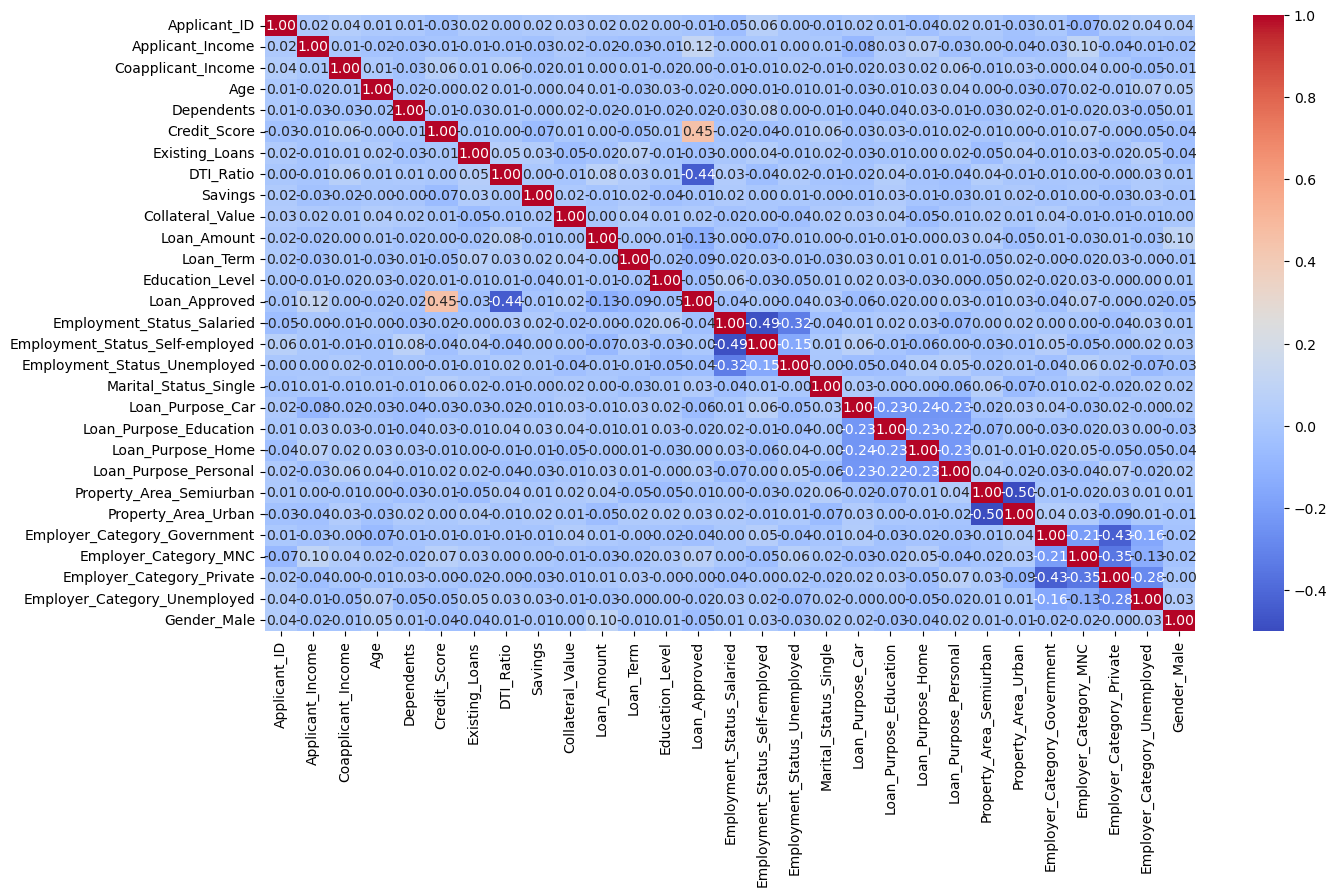

In [98]:
num_cols=df.select_dtypes(include="number")
corre_matrix=num_cols.corr()
plt.figure(figsize=(15,8))
sns.heatmap(
    corre_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [99]:
corre_matrix

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male
Applicant_ID,1.000000,0.020970,0.041140,0.014579,0.012495,-0.028170,0.024995,0.000174,0.022692,0.031759,...,0.005426,-0.039878,0.019178,0.012969,-0.030187,0.005906,-0.074056,0.022803,0.038417,0.036067
Applicant_Income,0.020970,1.000000,0.007545,-0.023988,-0.026658,-0.009818,-0.010457,-0.009107,-0.028358,0.018789,...,0.032794,0.074209,-0.031234,0.004845,-0.036260,-0.025011,0.102589,-0.044639,-0.011995,-0.020871
Coapplicant_Income,0.041140,0.007545,1.000000,0.014306,-0.026733,0.058423,0.012418,0.058078,-0.015047,0.009457,...,0.028000,0.016022,0.059549,-0.010058,0.030045,-0.001146,0.037640,0.004312,-0.047929,-0.010148
Age,0.014579,-0.023988,0.014306,1.000000,-0.018767,-0.004212,0.023330,0.007903,-0.000986,0.037382,...,-0.006283,0.029865,0.037293,0.003100,-0.025661,-0.066041,0.021232,-0.012960,0.072462,0.048402
Dependents,0.012495,-0.026658,-0.026733,-0.018767,1.000000,-0.007687,-0.026338,0.011498,-0.004981,0.023004,...,-0.044642,0.027343,-0.005785,-0.032278,0.024082,-0.009250,-0.018757,0.030197,-0.054147,0.013706
Credit_Score,-0.028170,-0.009818,0.058423,-0.004212,-0.007687,1.000000,-0.007130,0.002338,-0.065353,0.007865,...,0.026013,-0.008658,0.015324,-0.006946,0.004445,-0.007076,0.066736,-0.000049,-0.046087,-0.039739
Existing_Loans,0.024995,-0.010457,0.012418,0.023330,-0.026338,-0.007130,1.000000,0.047008,0.034435,-0.049916,...,-0.010035,0.001777,0.023212,-0.053971,0.035629,-0.009642,0.030520,-0.019306,0.045391,-0.038762
DTI_Ratio,0.000174,-0.009107,0.058078,0.007903,0.011498,0.002338,0.047008,1.000000,0.004663,-0.009622,...,0.040432,-0.014125,-0.036648,0.044898,-0.006156,-0.007214,0.002090,-0.003506,0.026018,0.009624
Savings,0.022692,-0.028358,-0.015047,-0.000986,-0.004981,-0.065353,0.034435,0.004663,1.000000,0.015481,...,0.032558,-0.012217,-0.028948,0.005438,0.016833,-0.011683,0.004381,-0.030208,0.027178,-0.006667
Collateral_Value,0.031759,0.018789,0.009457,0.037382,0.023004,0.007865,-0.049916,-0.009622,0.015481,1.000000,...,0.040406,-0.050975,-0.007120,0.020061,0.007975,0.035760,-0.013464,-0.014480,-0.009655,0.000897


In [104]:
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Applicant_ID                      -0.011167
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed    




Train Test Split+ feature Scaling


In [105]:

X=df.drop("Loan_Approved",axis=1)
y=df["Loan_Approved"]

In [106]:
X.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male
0,1.0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,2.0,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
2,3.0,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,4.0,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,5.0,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [107]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [108]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train_scaled=sc.fit_transform(X_train)
X_test_scaled=sc.transform(X_test)

Train and Evaluate


In [110]:
# logistic regression
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train_scaled,y_train)

y_predict=lr.predict( X_test_scaled)

# Evaluation
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
print("precision score: ",precision_score(y_test,y_predict))
print("accuracy score: ",accuracy_score(y_test,y_predict))
print("recall score: ",recall_score(y_test,y_predict))
print("confusion_matrix score: ",confusion_matrix(y_test,y_predict))
print("f1 score: ",f1_score(y_test,y_predict))


precision score:  0.7868852459016393
accuracy score:  0.87
recall score:  0.7868852459016393
confusion_matrix score:  [[126  13]
 [ 13  48]]
f1 score:  0.7868852459016393


In [116]:
# for Knn
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)
y_predict=knn.predict(X_test_scaled)

# Evaluation
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
print("precision score: ",precision_score(y_test,y_predict))
print("accuracy score: ",accuracy_score(y_test,y_predict))
print("recall score: ",recall_score(y_test,y_predict))
print("confusion_matrix score: ",confusion_matrix(y_test,y_predict))
print("f1 score: ",f1_score(y_test,y_predict))


precision score:  0.5957446808510638
accuracy score:  0.74
recall score:  0.45901639344262296
confusion_matrix score:  [[120  19]
 [ 33  28]]
f1 score:  0.5185185185185185


In [118]:
#naive bayes
from sklearn.naive_bayes import GaussianNB
nb= GaussianNB()
nb.fit(X_train_scaled,y_train)
y_predict=nb.predict(X_test_scaled)

# Evaluation
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
print("precision score: ",precision_score(y_test,y_predict))
print("accuracy score: ",accuracy_score(y_test,y_predict))
print("recall score: ",recall_score(y_test,y_predict))
print("confusion_matrix score: ",confusion_matrix(y_test,y_predict))
print("f1 score: ",f1_score(y_test,y_predict))


precision score:  0.8035714285714286
accuracy score:  0.865
recall score:  0.7377049180327869
confusion_matrix score:  [[128  11]
 [ 16  45]]
f1 score:  0.7692307692307693


Feature engineering


In [130]:
# transform features or add feature to get better model

df["DTI_Ratio_sq"]=df["DTI_Ratio"]**2
df["Credit_score_sq"]=df["Credit_Score"]**2

#df["Applicant_Income_log"]=np.log1p(df["Applicant_Income"])

X=df.drop(columns=["Loan_Approved","DTI_Ratio","Credit_Score"])
y=df["Loan_Approved"]



In [131]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# scaling
sc=StandardScaler()
X_train_scaled=sc.fit_transform(X_train)
X_test_scaled=sc.transform(X_test)

In [132]:
# logistic regression
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train_scaled,y_train)

y_predict=lr.predict( X_test_scaled)

# Evaluation
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
print("precision score: ",precision_score(y_test,y_predict))
print("accuracy score: ",accuracy_score(y_test,y_predict))
print("recall score: ",recall_score(y_test,y_predict))
print("confusion_matrix score: ",confusion_matrix(y_test,y_predict))
print("f1 score: ",f1_score(y_test,y_predict))

precision score:  0.7846153846153846
accuracy score:  0.88
recall score:  0.8360655737704918
confusion_matrix score:  [[125  14]
 [ 10  51]]
f1 score:  0.8095238095238095


In [133]:
#naive bayes
from sklearn.naive_bayes import GaussianNB
nb= GaussianNB()
nb.fit(X_train_scaled,y_train)
y_predict=nb.predict(X_test_scaled)

# Evaluation
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
print("precision score: ",precision_score(y_test,y_predict))
print("accuracy score: ",accuracy_score(y_test,y_predict))
print("recall score: ",recall_score(y_test,y_predict))
print("confusion_matrix score: ",confusion_matrix(y_test,y_predict))
print("f1 score: ",f1_score(y_test,y_predict))


precision score:  0.8076923076923077
accuracy score:  0.855
recall score:  0.6885245901639344
confusion_matrix score:  [[129  10]
 [ 19  42]]
f1 score:  0.7433628318584071
